#Predicting Winning in the MLB

####Importing packages and CSV file

In [1]:
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from scipy.stats import linregress

In [2]:
teams = pd.read_csv("data/Teams.csv")
teams.head()

,yearID,lgID,teamID,franchID,divID,Rank,G,Ghome,W,L,...,DP,FP,name,park,attendance,BPF,PPF,teamIDBR,teamIDlahman45,teamIDretro
0,1871,NaN,BS1,BNA,NaN,3,31,NaN,20,10,...,24.0,0.834,Boston Red Stockings,South End Grounds I,NaN,103.0,98.0,BOS,BS1,BS1
1,1871,NaN,CH1,CNA,NaN,2,28,NaN,19,9,...,16.0,0.829,Chicago White Stockings,Union Base-Ball Grounds,NaN,104.0,102.0,CHI,CH1,CH1
2,1871,NaN,CL1,CFC,NaN,8,29,NaN,10,19,...,15.0,0.818,Cleveland Forest Citys,National Association Grounds,NaN,96.0,100.0,CLE,CL1,CL1
3,1871,NaN,FW1,KEK,NaN,7,19,NaN,7,12,...,8.0,0.803,Fort Wayne Kekiongas,Hamilton Field,NaN,101.0,107.0,KEK,FW1,FW1
4,1871,NaN,NY2,NNA,NaN,5,33,NaN,16,17,...,14.0,0.840,New York Mutuals,Union Grounds (Brooklyn),NaN,90.0,88.0,NYU,NY2,NY2


###Filtering to work on teams in the modern era, defined here above 1980

In [3]:
teams_modern = teams[
    [
        "yearID",
        "W",
        "R",
        "G",
        "L",
        "H",
        "AB",
        "2B",
        "3B",
        "HR",
        "SO",
        "BB",
        "ERA",
    ]
]

teams_modern_filtered = (
    teams_modern[teams_modern["yearID"] > 1980]
    .reset_index(drop=True)
)

print(teams_modern_filtered.shape)
teams_modern_filtered.head()

(1292, 13)


,yearID,W,R,G,L,H,AB,2B,3B,HR,SO,BB,ERA
0,1981,50,395.0,107,56,886.0,3642.0,148.0,22.0,64.0,540.0,321.0,3.45
1,1981,59,429.0,105,46,883.0,3516.0,165.0,11.0,88.0,454.0,404.0,3.70
2,1981,59,519.0,108,49,1052.0,3820.0,168.0,17.0,90.0,520.0,378.0,3.81
3,1981,51,476.0,110,59,944.0,3688.0,134.0,16.0,97.0,571.0,393.0,3.70
4,1981,54,476.0,106,52,982.0,3615.0,135.0,27.0,76.0,518.0,322.0,3.47


###Creating WinPct, a derived feature using the win and loss column 

In [4]:
teams_modern_filtered["WinPct"] = (
    teams_modern_filtered["W"]
    / (teams_modern_filtered["W"] + teams_modern_filtered["L"])
)

teams_modern_filtered = teams_modern_filtered.drop(columns=["W", "L"])

teams_modern_filtered.head()

,yearID,R,G,H,AB,2B,3B,HR,SO,BB,ERA,WinPct
0,1981,395.0,107,886.0,3642.0,148.0,22.0,64.0,540.0,321.0,3.45,0.471698
1,1981,429.0,105,883.0,3516.0,165.0,11.0,88.0,454.0,404.0,3.70,0.561905
2,1981,519.0,108,1052.0,3820.0,168.0,17.0,90.0,520.0,378.0,3.81,0.546296
3,1981,476.0,110,944.0,3688.0,134.0,16.0,97.0,571.0,393.0,3.70,0.463636
4,1981,476.0,106,982.0,3615.0,135.0,27.0,76.0,518.0,322.0,3.47,0.509434


##Win Percentage vs. ERA

####Calculating regression statistics for our Win% vs ERA simple linear regression

In [5]:
x = teams_modern_filtered["ERA"]
y = teams_modern_filtered["WinPct"]

result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
r_squared = r_value ** 2

print("Slope:", slope)
print("Intercept:", intercept)
print("R-value:", r_value)
print("R-squared:", r_squared)

Slope: -0.07646069696899364
Intercept: 0.819568670839226
R-value: -0.5978459936272875
R-squared: 0.3574198320961987


####Plotting LSRL against the Win% vs ERA scatter plot

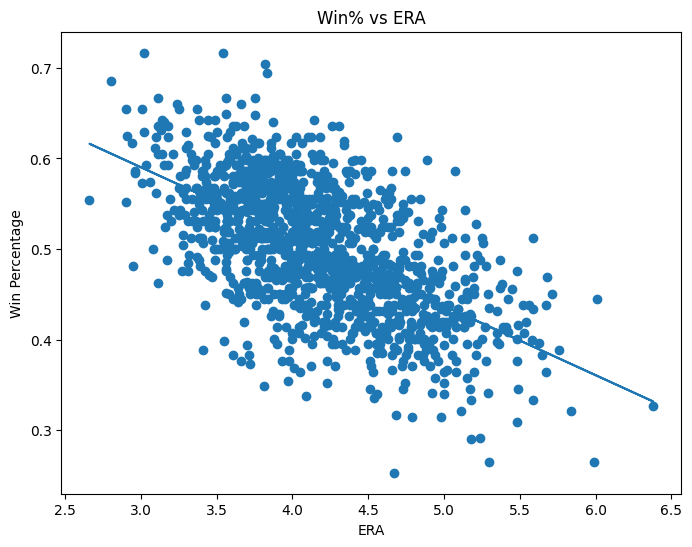

In [6]:
line = slope * x + intercept

plt.figure(figsize=(8, 6))
plt.scatter(x, y)
plt.plot(x, line)

plt.xlabel("ERA")
plt.ylabel("Win Percentage")
plt.title("Win% vs ERA")

plt.show()

##Win Percentage vs. Runs Per Game 

####Calculating regression statistics for our Win% vs Runs Per Game simple linear regression

In [7]:
teams_modern_filtered["R/G"] = (
    teams_modern_filtered["R"] / teams_modern_filtered["G"]
)

x = teams_modern_filtered["R/G"]
y = teams_modern_filtered["WinPct"]

result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
r_squared = r_value ** 2

print("Slope:", slope)
print("Intercept:", intercept)
print("R-value:", r_value)
print("R-squared:", r_squared)

Slope: 0.07406836380347928
Intercept: 0.16418500231533972
R-value: 0.5414387741310143
R-squared: 0.29315594613249546


####Plotting LSRL against the Win% vs Runs Per Game scatter plot

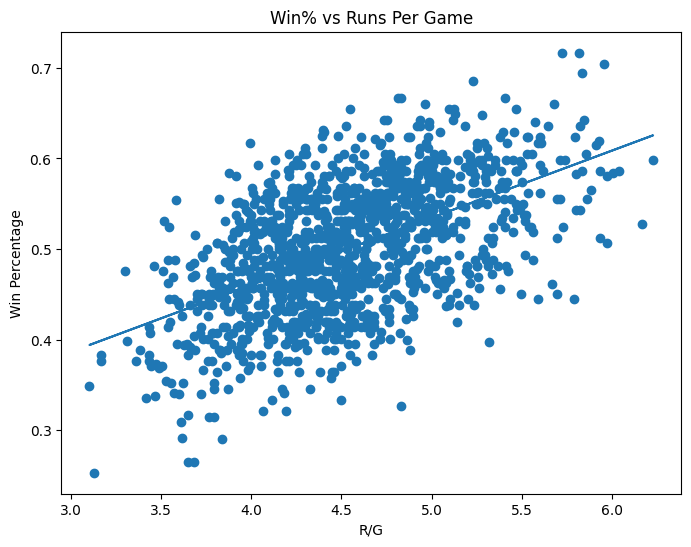

In [8]:
line = slope * x + intercept

plt.figure(figsize=(8, 6))
plt.scatter(x, y)
plt.plot(x, line)

plt.xlabel("R/G")
plt.ylabel("Win Percentage")
plt.title("Win% vs Runs Per Game")

plt.show()

##Win Percentage vs. Walks Per Game 

####Calculating regression statistics for our Win% vs Walks Per Game simple linear regression

In [9]:
teams_modern_filtered["BB/G"] = (
    teams_modern_filtered["BB"] / teams_modern_filtered["G"]
)

x = teams_modern_filtered["BB/G"]
y = teams_modern_filtered["WinPct"]

result = linregress(x, y)

slope = result.slope
intercept = result.intercept
r_value = result.rvalue
r_squared = r_value ** 2

print("Slope:", slope)
print("Intercept:", intercept)
print("R-value:", r_value)
print("R-squared:", r_squared)

Slope: 0.07218368061988309
Intercept: 0.2641955081307719
R-value: 0.43363515977112815
R-squared: 0.18803945178973183


####Plotting LSRL against the Win% vs Walks Per Game scatter plot

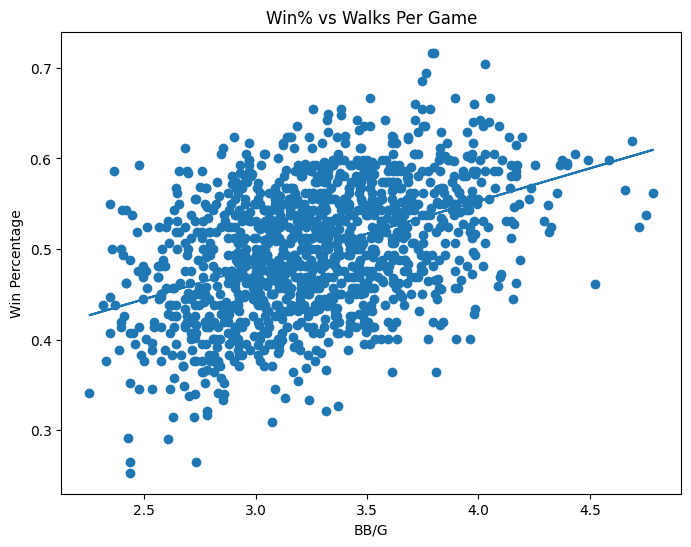

In [10]:
line = slope * x + intercept

plt.figure(figsize=(8, 6))
plt.scatter(x, y)
plt.plot(x, line)

plt.xlabel("BB/G")
plt.ylabel("Win Percentage")
plt.title("Win% vs Walks Per Game")

plt.show()

##Win Percentage vs. ERA, Runs Per Game, and Walks Per Game 

####Calculating regression statistics for our Win% vs ERA, Runs Per Game, and Walks Per Game multiple linear regression

In [11]:
X = teams_modern_filtered[["ERA", "R/G", "BB/G"]]
y = teams_modern_filtered["WinPct"]

model = LinearRegression()
model.fit(X, y)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print("R^2:", model.score(X, y))

Intercept: 0.463295344345964
Coefficients: [-0.09896076  0.09995403 -0.00086771]
R^2: 0.8559463318829932


####Plotting the predicted vs acutal win percentage

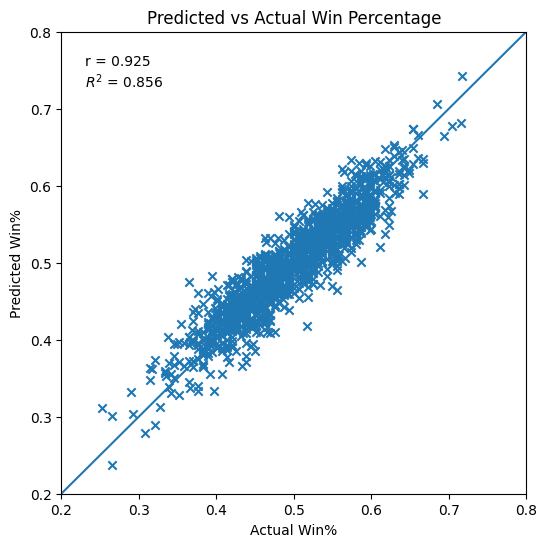

In [12]:
y_pred = model.predict(X)

r_squared = model.score(X, y)
r_value = r_squared ** 0.5

plt.figure(figsize=(6, 6))

plt.scatter(y, y_pred, marker="x")

plt.xlabel("Actual Win%")
plt.ylabel("Predicted Win%")
plt.title("Predicted vs Actual Win Percentage")

plt.plot([0, 1], [0, 1])

plt.xlim(0.2, 0.8)
plt.ylim(0.2, 0.8)

plt.text(
    0.05,
    0.95,
    f"r = {r_value:.3f}\n$R^2$ = {r_squared:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.show()

##Training and testing the multiple linear regression model

In [13]:
model_data = teams_modern_filtered[
    ["ERA", "R/G", "BB/G", "WinPct"]
].copy()

In [14]:
train = model_data.sample(frac=0.8, random_state=0)
test = model_data.drop(index=train.index)

y_train = train["WinPct"]
X_train = train.drop(columns=["WinPct"])

y_test = test["WinPct"]
X_test = test.drop(columns=["WinPct"])

lr = LinearRegression(fit_intercept=True)
lr.fit(X_train, y_train)

print("Train score:", lr.score(X_train, y_train))
print("Test score:", lr.score(X_test, y_test))

Train score: 0.8597259142372342
Test score: 0.8401086025386878


##Coefficient values of the multiple linear regression model

In [15]:
coefs = pd.DataFrame(
    lr.coef_,
    index=lr.feature_names_in_,
    columns=["Coefficient vals"]
)

coefs.loc["Intercept"] = lr.intercept_

coefs

,Coefficient vals
ERA,-0.097627
R/G,0.099553
BB/G,-0.000675
Intercept,0.458503
